# Chemical perturbation response prediction

**Yernur Kenzhegazin · Alan Berdigaliyev · Hugo Telles**  
M2 GENIOMHE-AI · Supervisor: Amaury Giard, IBISC

This notebook explains the data, models and evaluation. It reads the saved results, displays the main figures and runs a small prediction example when the model and data files are available. Full retraining is described below.

The question is whether chemical structure adds useful information beyond measured control expression, and whether that benefit transfers to unseen compounds, SKBR3 and external experiments. These test sets were inspected during model development, so the analyses are exploratory rather than independent confirmation.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

PROJECT = Path.cwd()
if not (PROJECT / 'extension/balanced').exists():
    raise FileNotFoundError('Open this notebook from the extracted project directory.')
BALANCED = PROJECT / 'extension/balanced'
sys.path.insert(0, str(PROJECT / 'extension'))
sys.path.insert(0, str(PROJECT / 'presentation'))
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__)
print('Results:', BALANCED.name)

Python: 3.13.7
NumPy: 2.5.4 | pandas: 3.1.1
Results: balanced


## 1. What the files mean

The treated-expression Feather file supplies targets. `compound_split.csv` fixes compound assignments and `sample_usage.feather` fixes eligible sample IDs. Measured DMSO profiles supply the untreated reference. A control group matches detection plate, cell, time and bead batch.

The original split labels are preserved for retained rows. Similarity screening and control availability remove rows; they do not create different training samples for the three encoders. The main comparison uses one common cohort.

In [2]:
audit = json.loads((BALANCED / 'generalization_audit.json').read_text())
verification = json.loads((BALANCED / 'verification.json').read_text())
display(pd.DataFrame({'profiles': audit['samples'], 'compounds': audit['compounds']}))
print('Integrity checks:', verification['status'])
print('Internal test profiles sharing a training control group:', audit['test_profiles_with_control_group_seen_in_train'])
print('Internal test compounds with a training analogue above 0.7:', audit['test_compounds_above_0_7_similarity_to_train'])
print('Test compounds with identical ECFP4 to training:', audit['test_compounds_with_identical_ECFP4_to_training'])

Integrity checks: passed
Internal test profiles sharing a training control group: 27752
Internal test compounds with a training analogue above 0.7: 545
Test compounds with identical ECFP4 to training: 295


,profiles,compounds
train,210438,8168
val,25190,1029
test,27765,1019


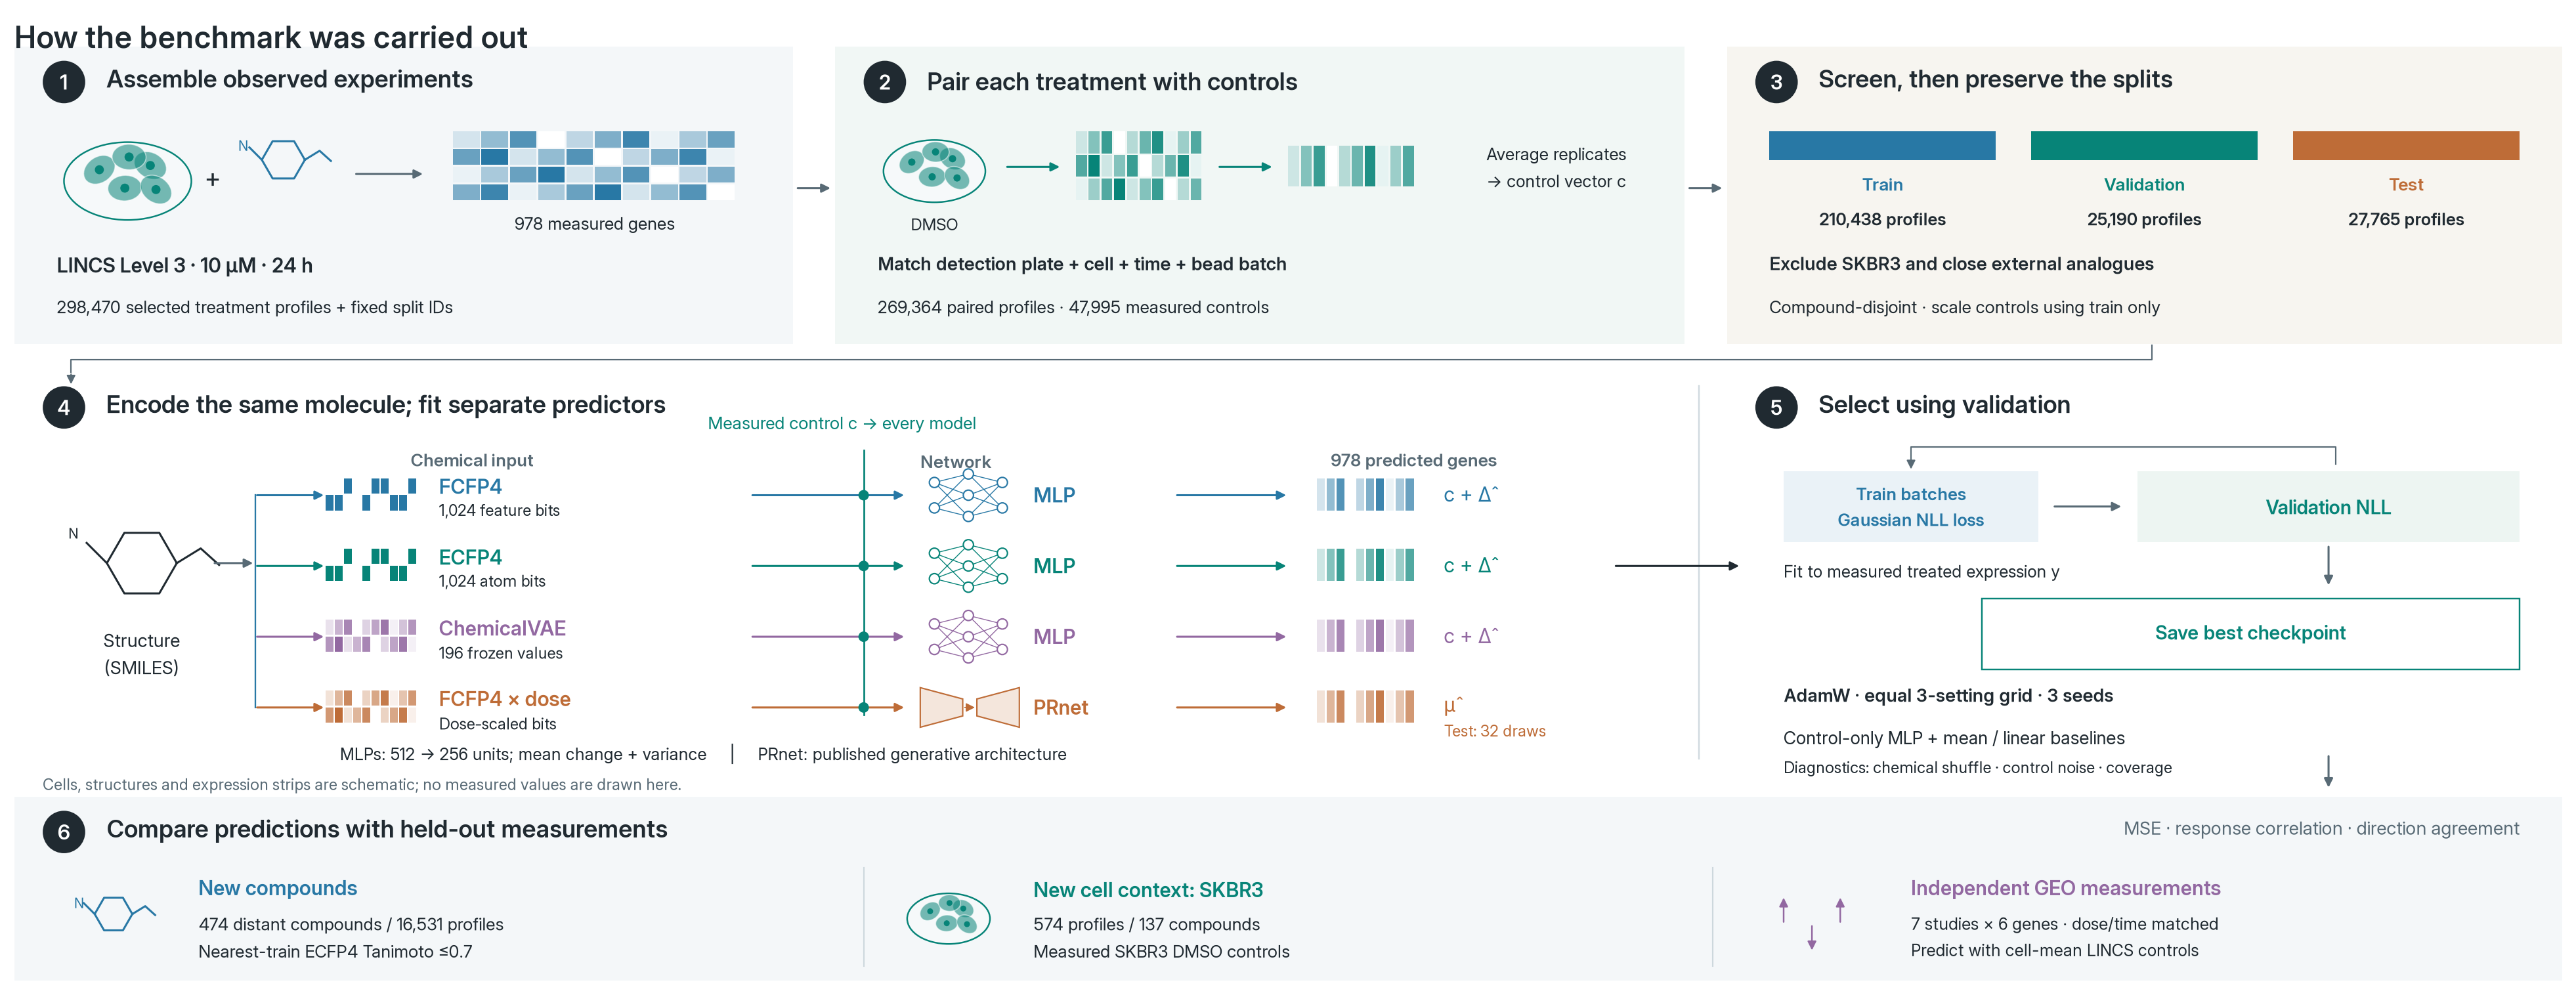

In [3]:
display(Image(filename=str(PROJECT / 'presentation/figures/pipeline.png'), width=1100))

The diagram follows six steps:

1. Assemble the supplied treated profiles, compound assignments and sample IDs.
2. Match measured DMSO controls by plate, cell, time and bead batch, and average replicates.
3. Screen the cohort, retain the supplied split labels and estimate control scaling from training inputs only.
4. Encode each compound as FCFP4, ECFP4 or ChemicalVAE features for separate MLPs; fit PRnet with dose-scaled FCFP4.
5. Select settings and checkpoints using validation NLL, with the same tuning budget and three seeds.
6. Compare held-out predictions with measurements and baselines, then examine chemical dependence, noise and uncertainty.

Cell icons, feature grids and expression strips are schematic. Their colors do not represent measured values; sample counts and result plots come from the saved analyses. External GEO predictions use a cell-specific mean of LINCS control groups. GEO treated and control samples determine the observed gene directions, so platform differences remain.

## 2. Models and fitting

FCFP4 describes local functional classes, ECFP4 describes local atom environments, and ChemicalVAE supplies a frozen 196-value molecular embedding. FCFP4 and ECFP4 each have 1,024 bits and radius 2. Each representation enters a separate MLP with the measured control vector.

The residual MLP computes `treated_mean = control + response`. The response head starts at zero; a positive variance head supports Gaussian NLL training. Cell context is encoded by control expression, not a cell-ID embedding. PRnet uses the published PGM architecture, FCFP4 dose encoding and decoder noise. Its final mean averages 32 fixed draws.

Five main models receive three training seeds and the same three-setting AdamW tuning budget. Seed 42 validation NLL selects the setting; every checkpoint is selected by its own validation NLL. Test labels do not select settings. The comparison does not establish globally optimal tuning for any architecture.

,model,setting,val_nll,best_epoch,selected
0,ResidualFCFP4,default,0.108004,2,False
1,ResidualFCFP4,lower_lr,0.097477,7,False
2,ResidualFCFP4,lower_decay,0.088339,7,True
3,Residual,default,0.084649,7,False
4,Residual,lower_lr,0.083725,7,True
5,Residual,lower_decay,0.092873,2,False
6,ResidualChemicalVAE,default,0.110533,4,False
7,ResidualChemicalVAE,lower_lr,0.089919,17,True
8,ResidualChemicalVAE,lower_decay,0.102323,7,False
9,PRnet,default,0.292255,15,False


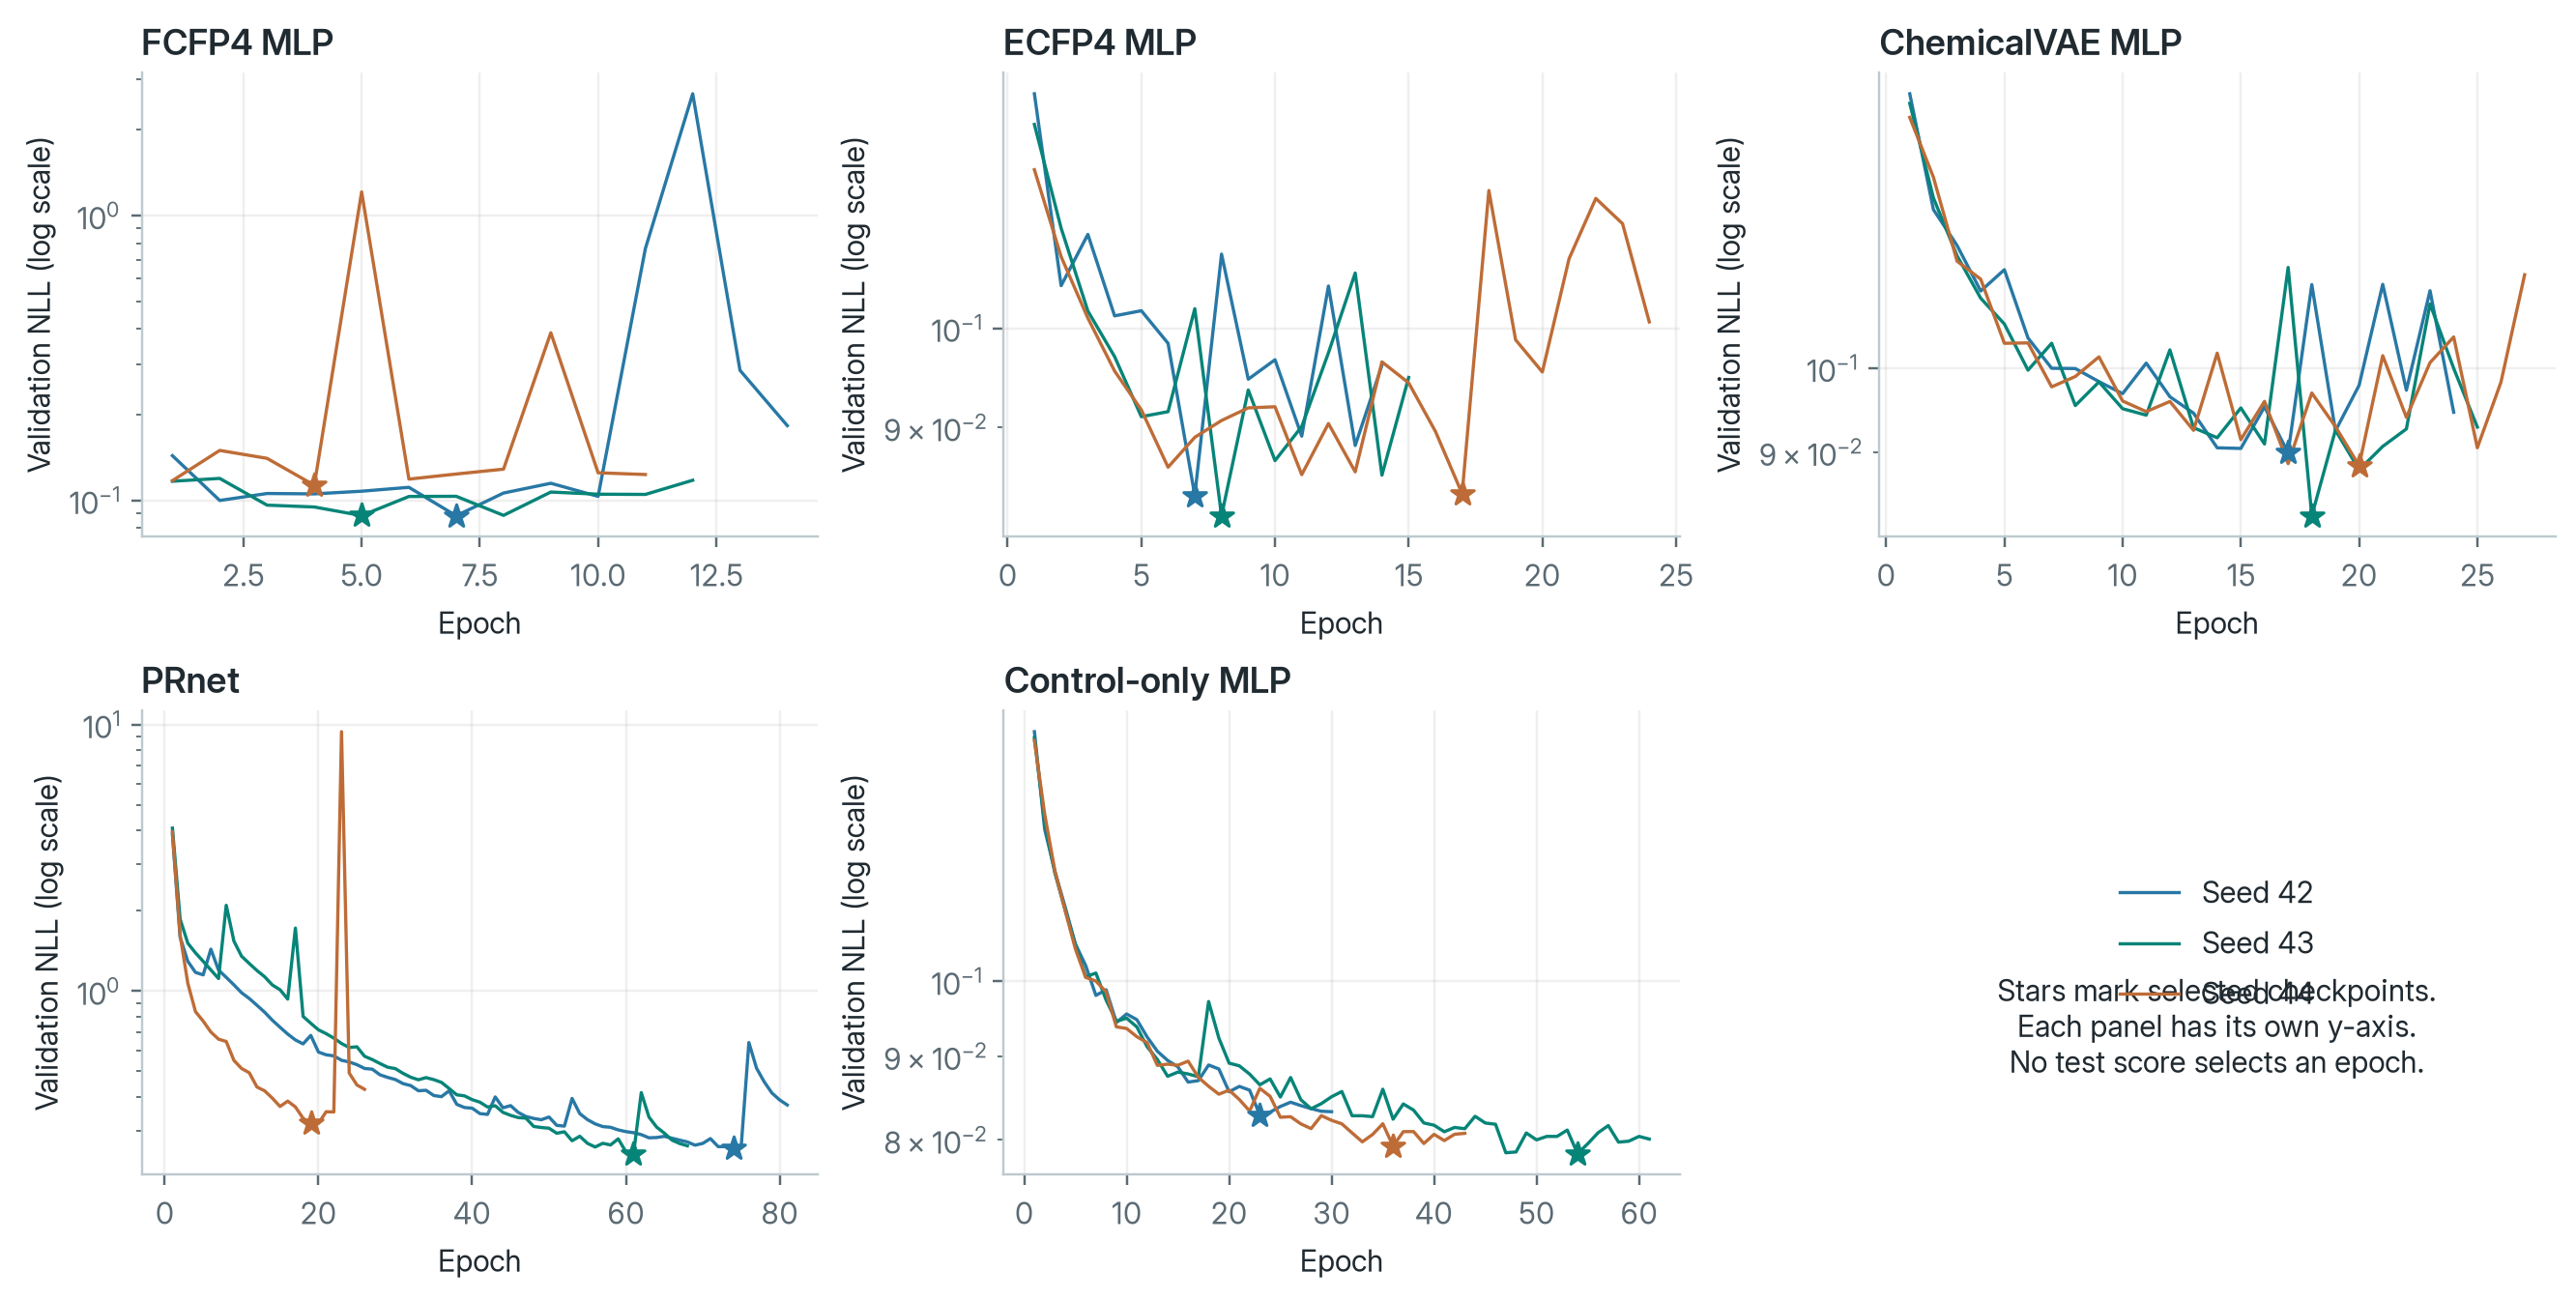

In [4]:
selected = json.loads((BALANCED / 'selected_settings.json').read_text())
tuning = pd.read_csv(BALANCED / 'tuning_validation.csv')
display(tuning.assign(selected=tuning.apply(lambda r: selected[r['model']] == r['setting'], axis=1)))
display(Image(filename=str(PROJECT / 'presentation/figures/training_convergence.png'), width=1100))

## 3. Run a saved model on held-out samples

The following cell loads eight internal test rows and the validation-selected ECFP4 checkpoint. It uses the same data loader and inference function as the full benchmark. These eight rows demonstrate execution; their MSE is not the headline test score. The example is skipped when large data or checkpoint files are absent. Restore these files from the full submission archive as described in `docs/DATA.md`. The saved tables and figures can be read without them.

In [5]:
setting = selected['Residual']
folder = BALANCED / 'weights' if setting == 'default' else BALANCED / 'tuning' / setting
required = [
    PROJECT / 'extension/split_indices.npz',
    PROJECT / 'extension/scaling.npz',
    PROJECT / 'MLP_PRnet_controls/data/sample_manifest.feather',
    PROJECT / 'MLP_PRnet_controls/prepared/indices.npz',
    PROJECT / 'MLP_PRnet_controls/data/chemical_features.npz',
    PROJECT / 'MLP_PRnet_controls/prepared/targets.npy',
    PROJECT / 'MLP_PRnet_controls/data/control_means.npy',
    folder / 'Residual_42.pt',
]
if not all(path.is_file() for path in required):
    print('Prediction example skipped: data or checkpoints are missing. '
          'Restore the assets from the full submission archive; see docs/DATA.md.')
else:
    import torch
    from benchmark import build
    from scientific_data import load_internal, infer

    torch.set_num_threads(4)
    indices = np.load(PROJECT / 'extension/split_indices.npz')['test'][:8]
    example = load_internal(indices)
    network = build('Residual')
    network.load_state_dict(torch.load(folder / 'Residual_42.pt', map_location='cpu', weights_only=True))
    prediction = infer(network, 'Residual', example['features']['ECFP4'], example['control'])
    assert prediction.shape == example['y'].shape == (8, 978)
    assert np.isfinite(prediction).all()
    display(pd.DataFrame({'sample_id': example['sample_id'],
                          'model_mse': ((prediction - example['y']) ** 2).mean(1),
                          'control_mse': ((example['control'] - example['y']) ** 2).mean(1)}))

,sample_id,model_mse,control_mse
0,LJP009_A549_24H_X3_F1B19:O01,1.222422,1.357059
1,DOSBIO001_PC3_24H_X2_B11:F14,0.318928,0.380261
2,DOSBIO002_A549_24H_X3_B12:N07,0.231667,0.265205
3,ERG015_VCAP_24H_X1_B10_DUO52HI53LO:D18,0.465171,0.512087
4,DOSBIO001_NPC_24H_X2_B12:H04,0.282788,0.299423
5,DOSBIO001_A375_24H_X2_B11:I22,0.213419,0.231702
6,DOSBIO001_A375_24H_X3_B11:O07,0.402453,0.481499
7,DOSBIO001_A549_24H_X2_B11:N22,0.294621,0.249159


## 4. Full benchmark and simple baselines

The main scores below average three independently initialized model runs. They are not ensemble scores. The linear model, global mean response, cell mean response and unchanged-control baselines provide additional tests of complexity. Cell mean response falls back to the global training response for unseen SKBR3.

The low-similarity subset contains 474 compounds / 16,531 profiles with nearest-training ECFP4 similarity at most 0.7. It avoids fingerprint-identical training analogues present in the original compound-disjoint split, but still shares some control groups with training. It is a subset of the existing test, not newly collected evidence.

MSE measures treated-expression reconstruction. Response correlation and direction measure treatment-minus-control changes. Lower MSE need not imply better regulation prediction or useful drug ranking.

,dataset,model,seeds,mse_mean,mse_seed_sd,macro_compound_mse,response_pearson,direction_accuracy
0,internal,CellMeanResponse,1,0.722365,NaN,0.755733,0.140589,0.606496
1,internal,DMSO,1,0.749482,NaN,0.775514,NaN,NaN
2,internal,GlobalMeanResponse,1,0.735685,NaN,0.765462,0.106508,0.586917
3,internal,RidgeECFP4,1,0.644459,NaN,0.664306,0.289963,0.702915
6,skbr3,CellMeanResponse,1,0.550536,NaN,0.618808,0.141195,0.614623
7,skbr3,DMSO,1,0.568916,NaN,0.644786,NaN,NaN
8,skbr3,GlobalMeanResponse,1,0.550536,NaN,0.618808,0.141195,0.614623
9,skbr3,RidgeECFP4,1,1.040409,NaN,1.070280,0.129468,0.593668
48,internal,ControlOnly,3,0.668160,0.001632,0.688335,0.236280,0.679749
49,internal,PRnet,3,0.894394,0.039196,0.891352,0.192035,0.638652


,dataset,model,mse_mean,mse_seed_sd
10,internal,ControlOnly,0.675117,0.001750
11,internal,Direct,0.785265,0.045851
12,internal,DirectZeroInit,0.799475,0.009489
13,internal,PRnet,0.946027,0.083498
14,internal,Residual,0.680879,0.009656
15,internal,ResidualChemicalVAE,0.707070,0.039642
16,internal,ResidualFCFP4,0.691726,0.014608
17,internal,ResidualRandomInit,0.685055,0.007948
18,skbr3,ControlOnly,0.566390,0.011119
19,skbr3,Direct,4.126157,0.754754


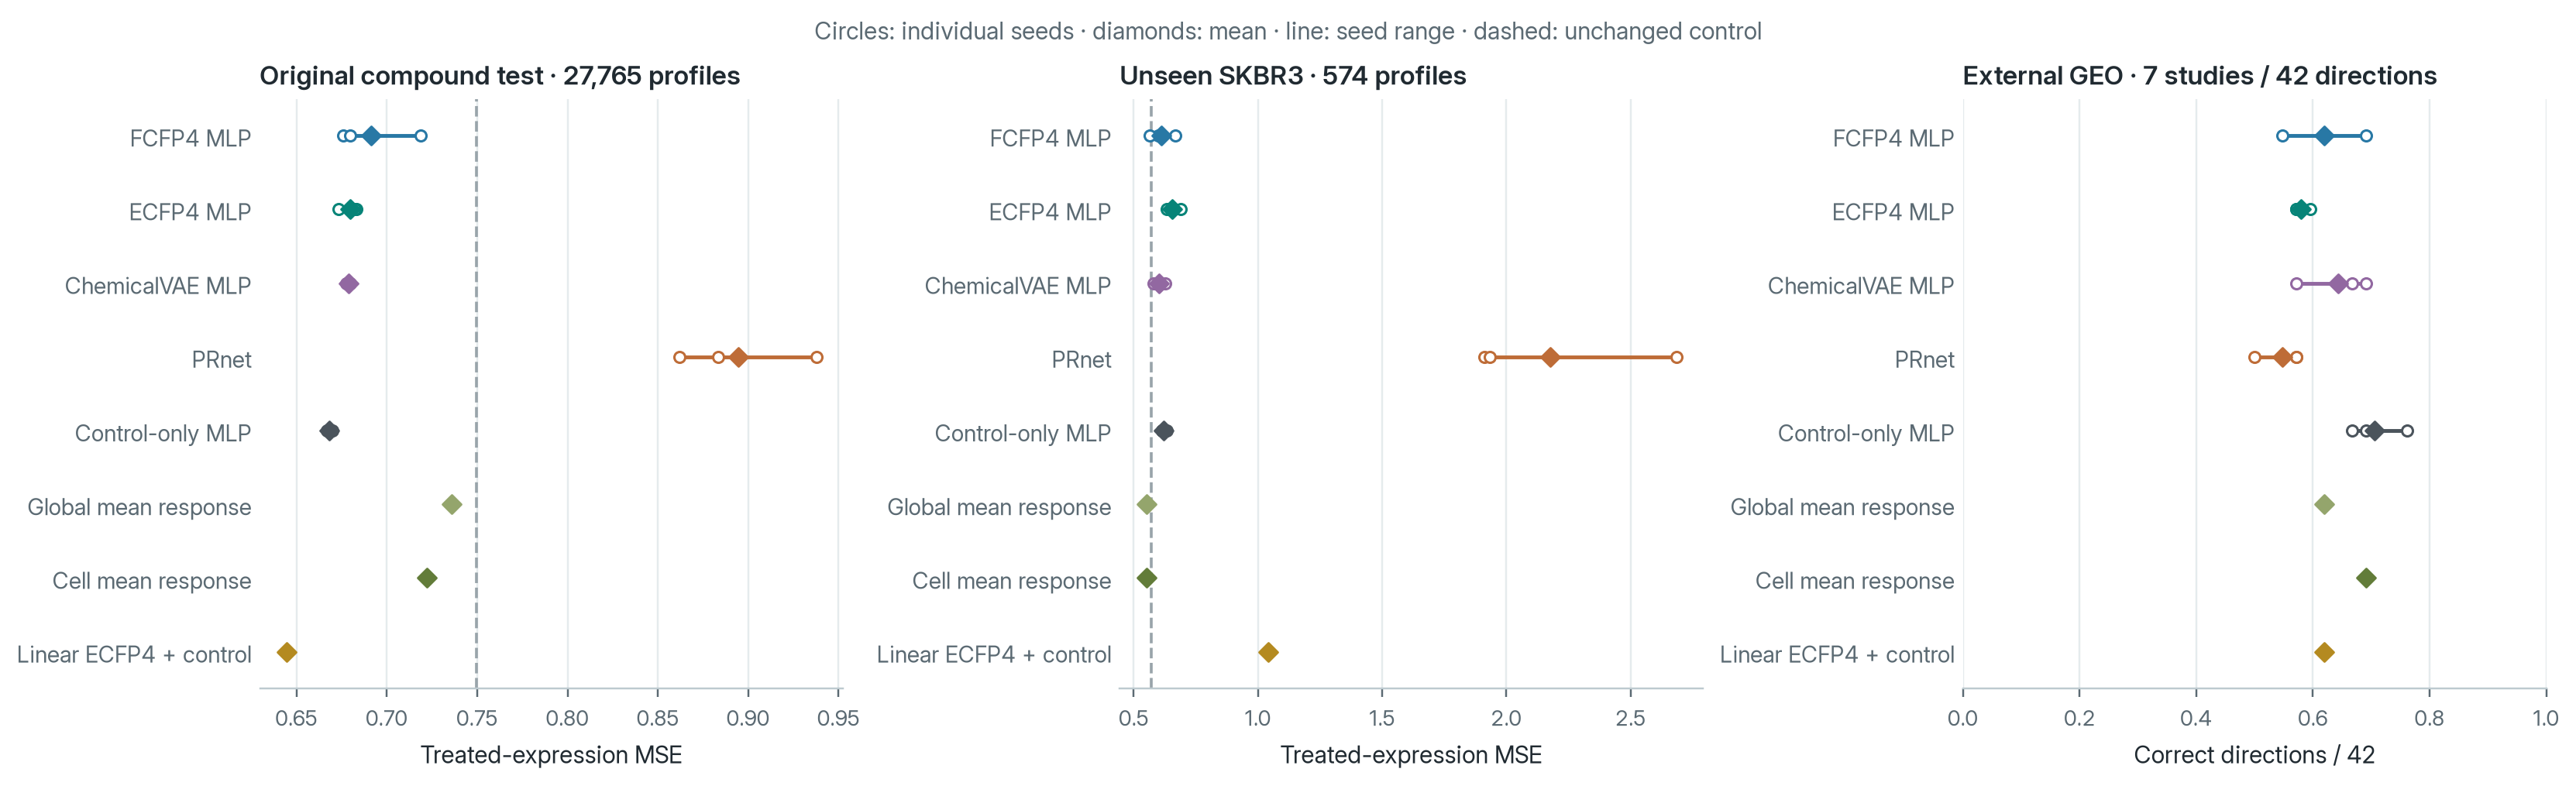

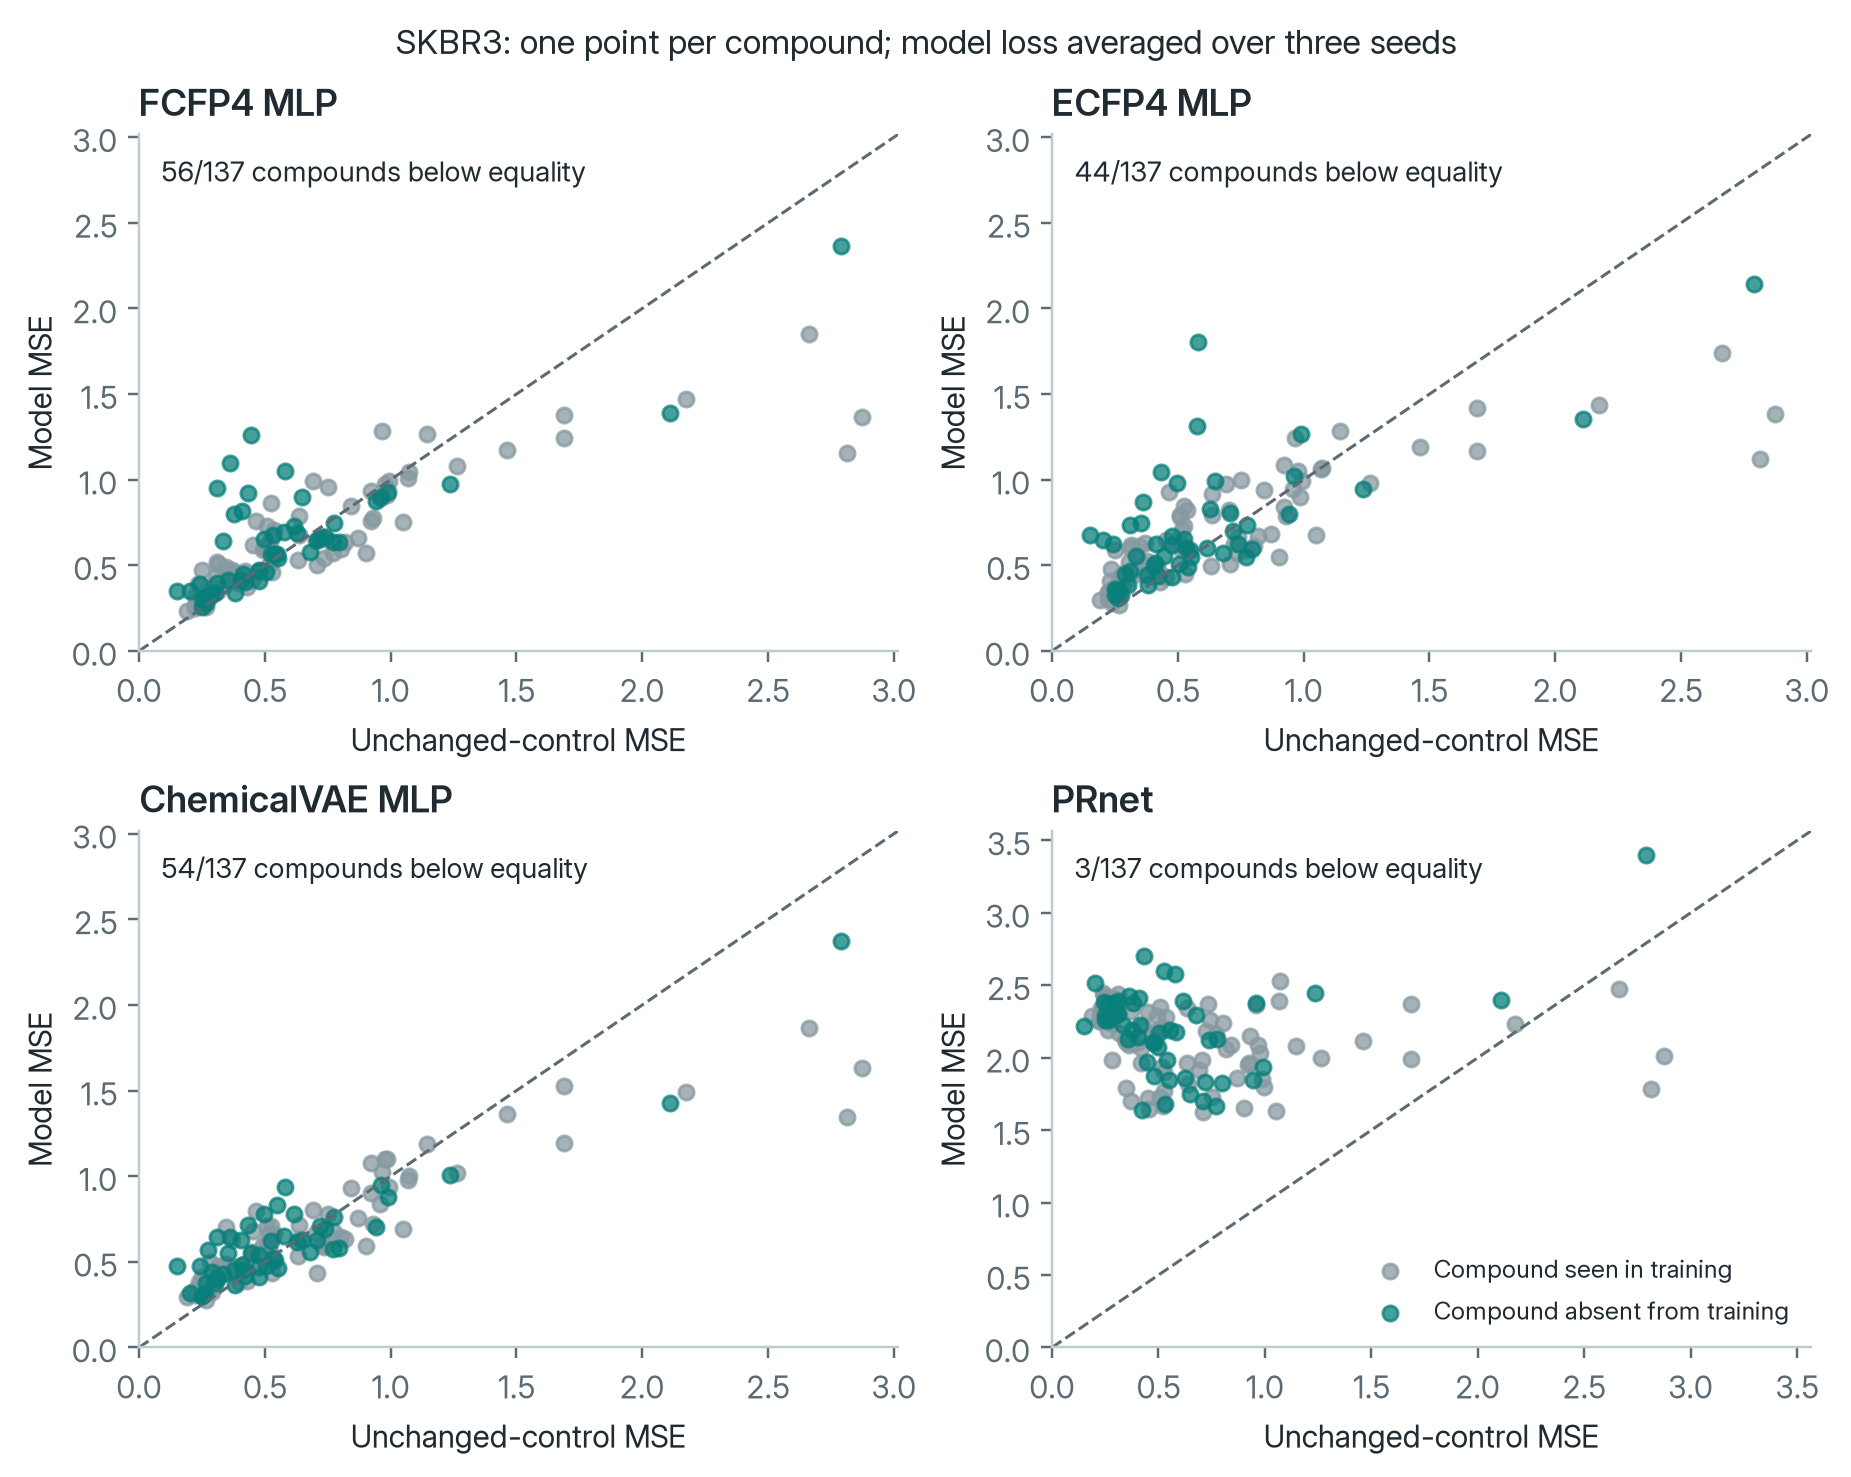

In [6]:
summary = pd.read_csv(BALANCED / 'summary/model_summary.csv')
main = summary.loc[summary.phase.isin(['tuned', 'baseline']) & summary.dataset.isin(['internal', 'internal_low_similarity', 'skbr3'])]
display(main[['dataset','model','seeds','mse_mean','mse_seed_sd','macro_compound_mse','response_pearson','direction_accuracy']])
fixed = summary.loc[summary.phase.eq('fixed') & summary.dataset.isin(['internal','skbr3'])]
display(fixed[['dataset','model','mse_mean','mse_seed_sd']])
display(Image(filename=str(PROJECT / 'presentation/figures/benchmark.png'), width=1200))
display(Image(filename=str(PROJECT / 'presentation/figures/compound_response.png'), width=1000))

## 5. Does the model use chemical information?

For each trained model, chemical features are shuffled within matched control groups while targets, controls and PRnet decoder draws remain fixed. The control-only model must be unchanged. A shuffling penalty indicates input dependence under this diagnostic; it does not prove a causal mechanism or improvement over a separately fitted control-only model.

Paired intervals resample compounds after averaging per-run losses. Control-group intervals are provided separately. Neither approach completely models crossed dependence between chemical compounds and experimental groups.

clean_mse  ...  mse_increase
dataset                 model                           ...              
internal                ControlOnly           0.668160  ...      0.000000
                        PRnet                 0.894394  ...      0.008422
                        Residual              0.679572  ...      0.015255
                        ResidualChemicalVAE   0.678904  ...      0.002952
                        ResidualFCFP4         0.691325  ...      0.011063
internal_low_similarity ControlOnly           0.656115  ...      0.000000
                        PRnet                 0.905493  ...      0.007001
                        Residual              0.672279  ...      0.012231
                        ResidualChemicalVAE   0.667116  ...      0.002867
                        ResidualFCFP4         0.689211  ...      0.007783
skbr3                   ControlOnly           0.619839  ...      0.000000
                        PRnet                 2.175858  ...      0.024314
                        Residual              0.653728  ...      0.056604
                        ResidualChemicalVAE   0.600906  ...      0.024530
                        ResidualFCFP4         0.610187  ...      0.060646

[15 rows x 3 columns]

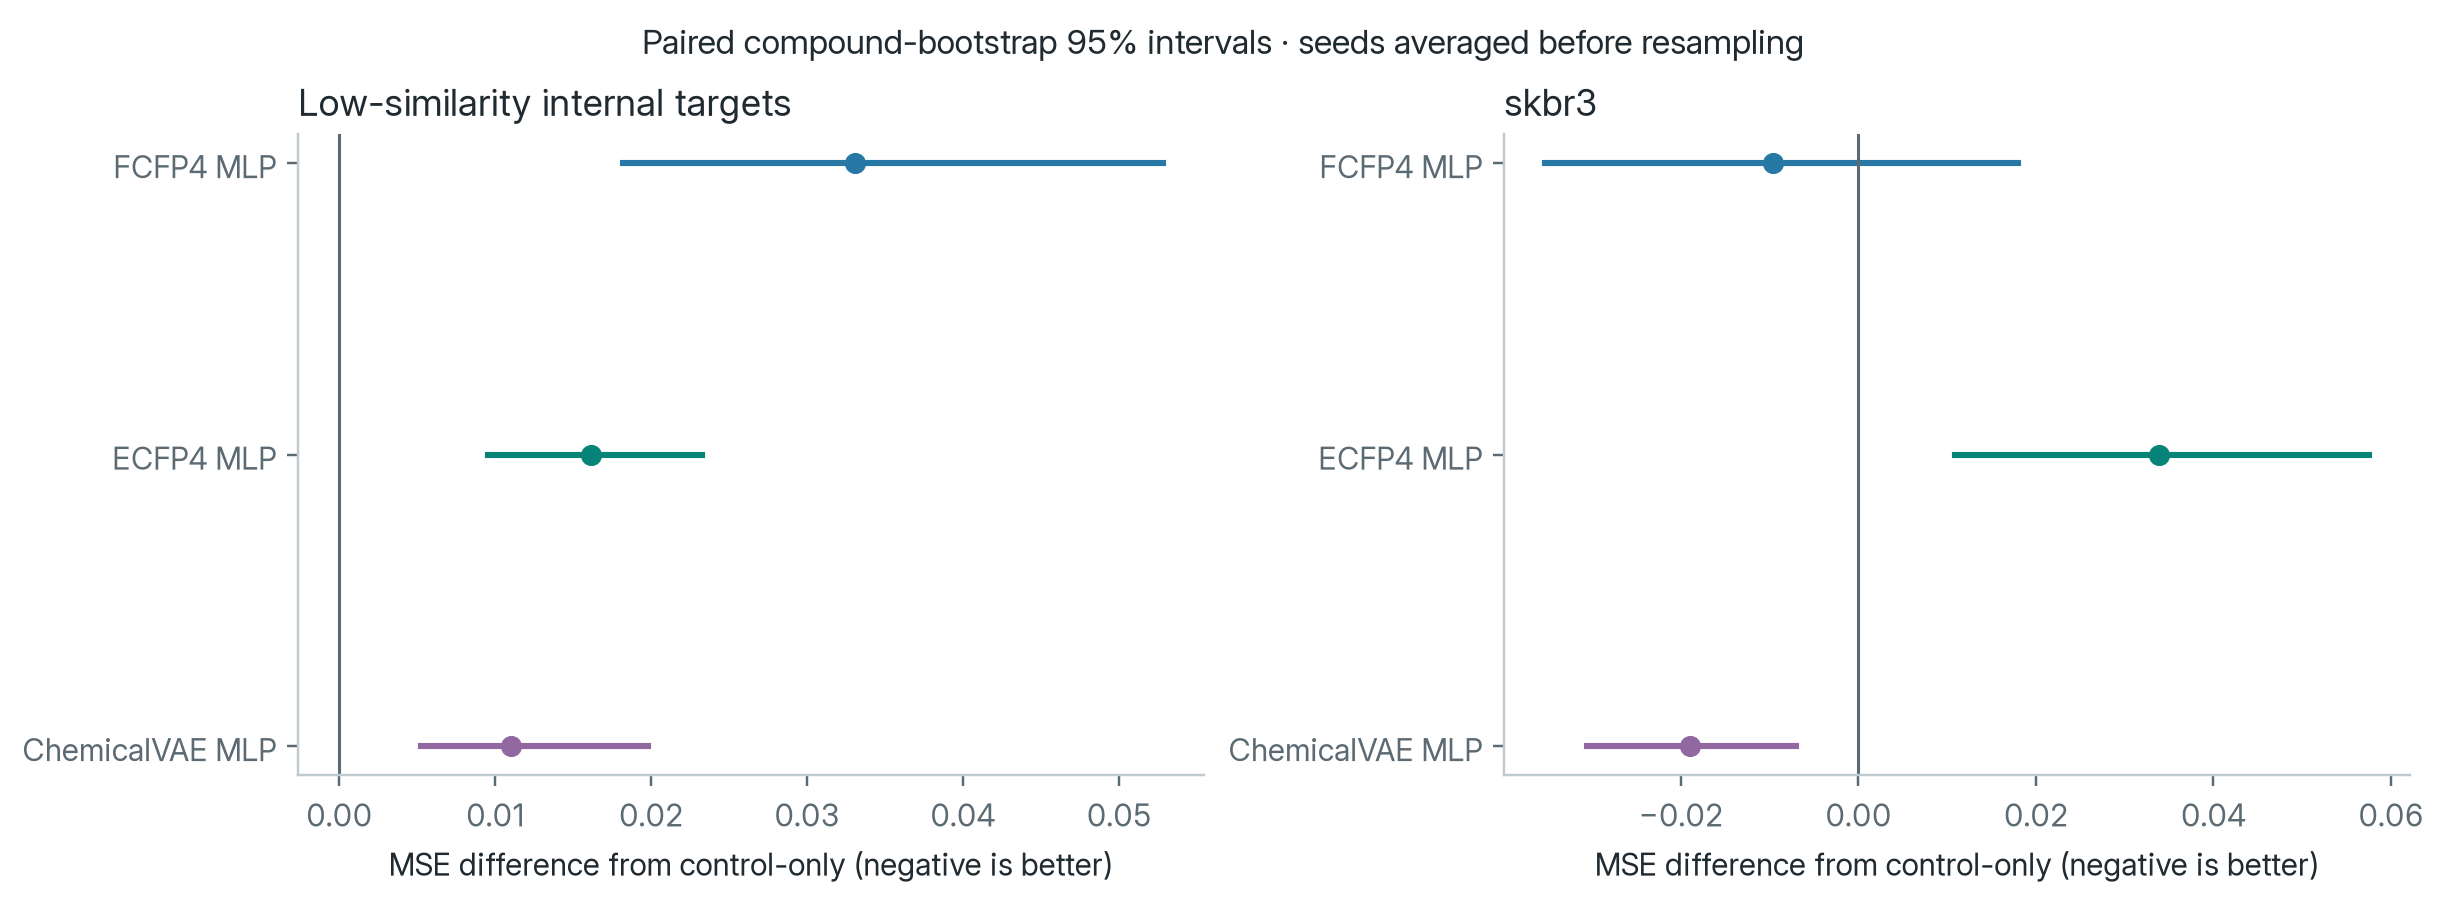

In [7]:
permutation = pd.read_csv(BALANCED / 'diagnostics/permutation_seed_means.csv')
assert permutation.loc[permutation.model.eq('ControlOnly'),'mse_increase'].eq(0).all()
display(permutation.groupby(['dataset','model'])[['clean_mse','shuffled_mse','mse_increase']].mean())
display(Image(filename=str(PROJECT / 'presentation/figures/chemical_added_value.png'), width=1000))

## 6. Dose-matched external regulation

Seven eligible GEO studies each contribute six genes at 10 µM and 24 hours. Forty-two directions are not 42 independent experiments: genes in the same study share samples and context. Twenty-seven directions have separated replicates; fifteen also pass the descriptive absolute-change threshold of 0.5 on their log-expression scale.

Observed directions use GEO treated and control samples. Predictions use LINCS cell-matched control references, so platform and culture differences remain. Norepinephrine is excluded because it has a training analogue. Small changes can have uncertain signs; the sensitivity subsets are not significance tests.

### Reading the external-study heatmap

Each row is one compound tested in one cell type; each column is a model. For AKT1, AURKB, EGFR, PIK3CA, SMAD3 and TP53, we ask whether the predicted increase or decrease relative to controls agrees with the direction measured in the GEO experiment.

Each cell counts correct directions out of six, averaged over three independently seeded training runs. Values range from 0 to 6: higher values and darker shading indicate more correct directions. A value of **6.0** means all six genes were correct in every run. **4.7** is a rounded mean across the three runs, not a gene-expression value or a percentage. This score measures direction, not the size of the expression change. The seven studies remain the independent clusters for uncertainty estimation.

,genes,separated,clear
gse_id,,,
GSE113505,6,3,3
GSE153871,6,5,1
GSE200700,6,3,0
GSE225537,6,2,2
GSE2450,6,4,4
GSE42872,6,5,4
GSE59008,6,5,1


,phase,model,seed,sum,size,mean
28,tuned,ControlOnly,42,32,42,0.761905
29,tuned,ControlOnly,43,29,42,0.690476
30,tuned,ControlOnly,44,28,42,0.666667
31,tuned,PRnet,42,21,42,0.500000
32,tuned,PRnet,43,24,42,0.571429
33,tuned,PRnet,44,24,42,0.571429
34,tuned,Residual,42,24,42,0.571429
35,tuned,Residual,43,24,42,0.571429
36,tuned,Residual,44,25,42,0.595238
37,tuned,ResidualChemicalVAE,42,28,42,0.666667


,model,reference,cluster,difference,lower,upper,clusters
0,ResidualFCFP4,PRnet,GEO study,0.071429,-0.079365,0.214286,7
1,Residual,PRnet,GEO study,0.031746,-0.135119,0.190476,7
2,ResidualChemicalVAE,PRnet,GEO study,0.095238,-0.031746,0.222222,7
3,ControlOnly,PRnet,GEO study,0.158730,-0.015873,0.333532,7
4,ResidualFCFP4,ControlOnly,GEO study,-0.087302,-0.166667,-0.015873,7
5,Residual,ControlOnly,GEO study,-0.126984,-0.206349,-0.047421,7
6,ResidualChemicalVAE,ControlOnly,GEO study,-0.063492,-0.182540,0.055556,7
7,PRnet,ControlOnly,GEO study,-0.158730,-0.333532,0.015873,7


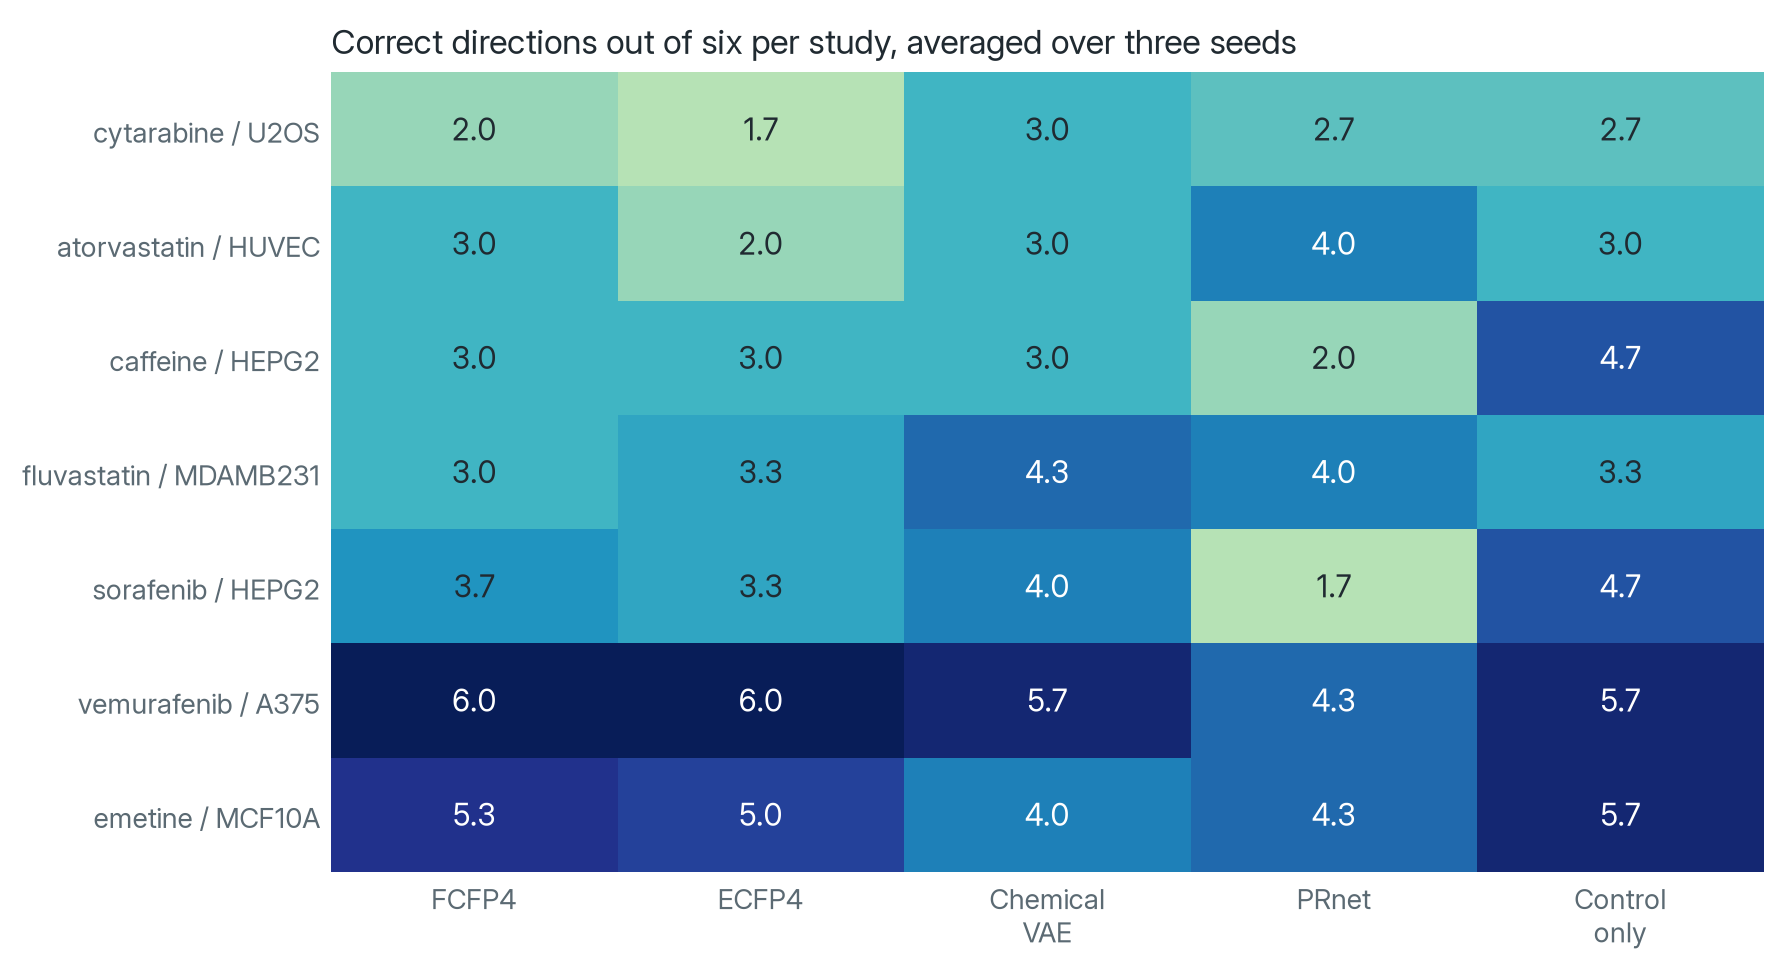

In [8]:
labels = pd.read_csv(PROJECT / 'dose_matched/measured_effects.csv')
labels = labels.loc[labels.chemical_split.eq('eligible')]
display(labels.groupby('gse_id').agg(genes=('genes','size'), separated=('separated_replicates','sum'), clear=('clear_change','sum')))
display(pd.read_csv(BALANCED / 'summary/external_seed_counts.csv').query("phase == 'tuned'"))
display(pd.read_csv(BALANCED / 'summary/paired_external_intervals.csv'))
display(Image(filename=str(PROJECT / 'presentation/figures/external_studies.png'), width=850))

## 7. Robustness, uncertainty and stricter separation

Synthetic Gaussian noise perturbs control inputs using the measured within-plate replicate SD. These technical repeats are not biological replicates and do not model every source of transcriptomic noise. Predictive intervals are marginal profile-gene intervals, not simultaneous coverage of the full expression vector.

A secondary split removes control groups from training and validation while preserving compound assignments. Its test groups and compounds are both unseen in fitting. The training set is also smaller, so any change cannot be attributed purely to group reuse. A 2 × 2 ablation separates the residual connection from zero mean-head initialization.

nll  covered95   width95
dataset  model                                             
internal ControlOnly          0.079324   0.952011  2.863265
         PRnet                0.285306   0.957683  3.535233
         Residual             0.107368   0.943634  2.736351
         ResidualChemicalVAE  0.120937   0.943922  2.764256
         ResidualFCFP4        0.117698   0.945419  2.792288
skbr3    ControlOnly          0.206578   0.967762  3.425279
         PRnet                0.952415   0.896193  5.005814
         Residual             0.233193   0.977981  3.706296
         ResidualChemicalVAE  0.190198   0.972963  3.470912
         ResidualFCFP4        0.180060   0.975660  3.497607

,clean_mse,half_control_mse,prediction_rms_change
model,,,
ControlOnly,0.619839,0.639613,0.130953
DMSO,0.568916,0.586212,0.131147
PRnet,2.175858,2.174555,0.070690
Residual,0.653728,0.673691,0.131364
ResidualChemicalVAE,0.600906,0.620874,0.132381
ResidualFCFP4,0.610187,0.629884,0.133084


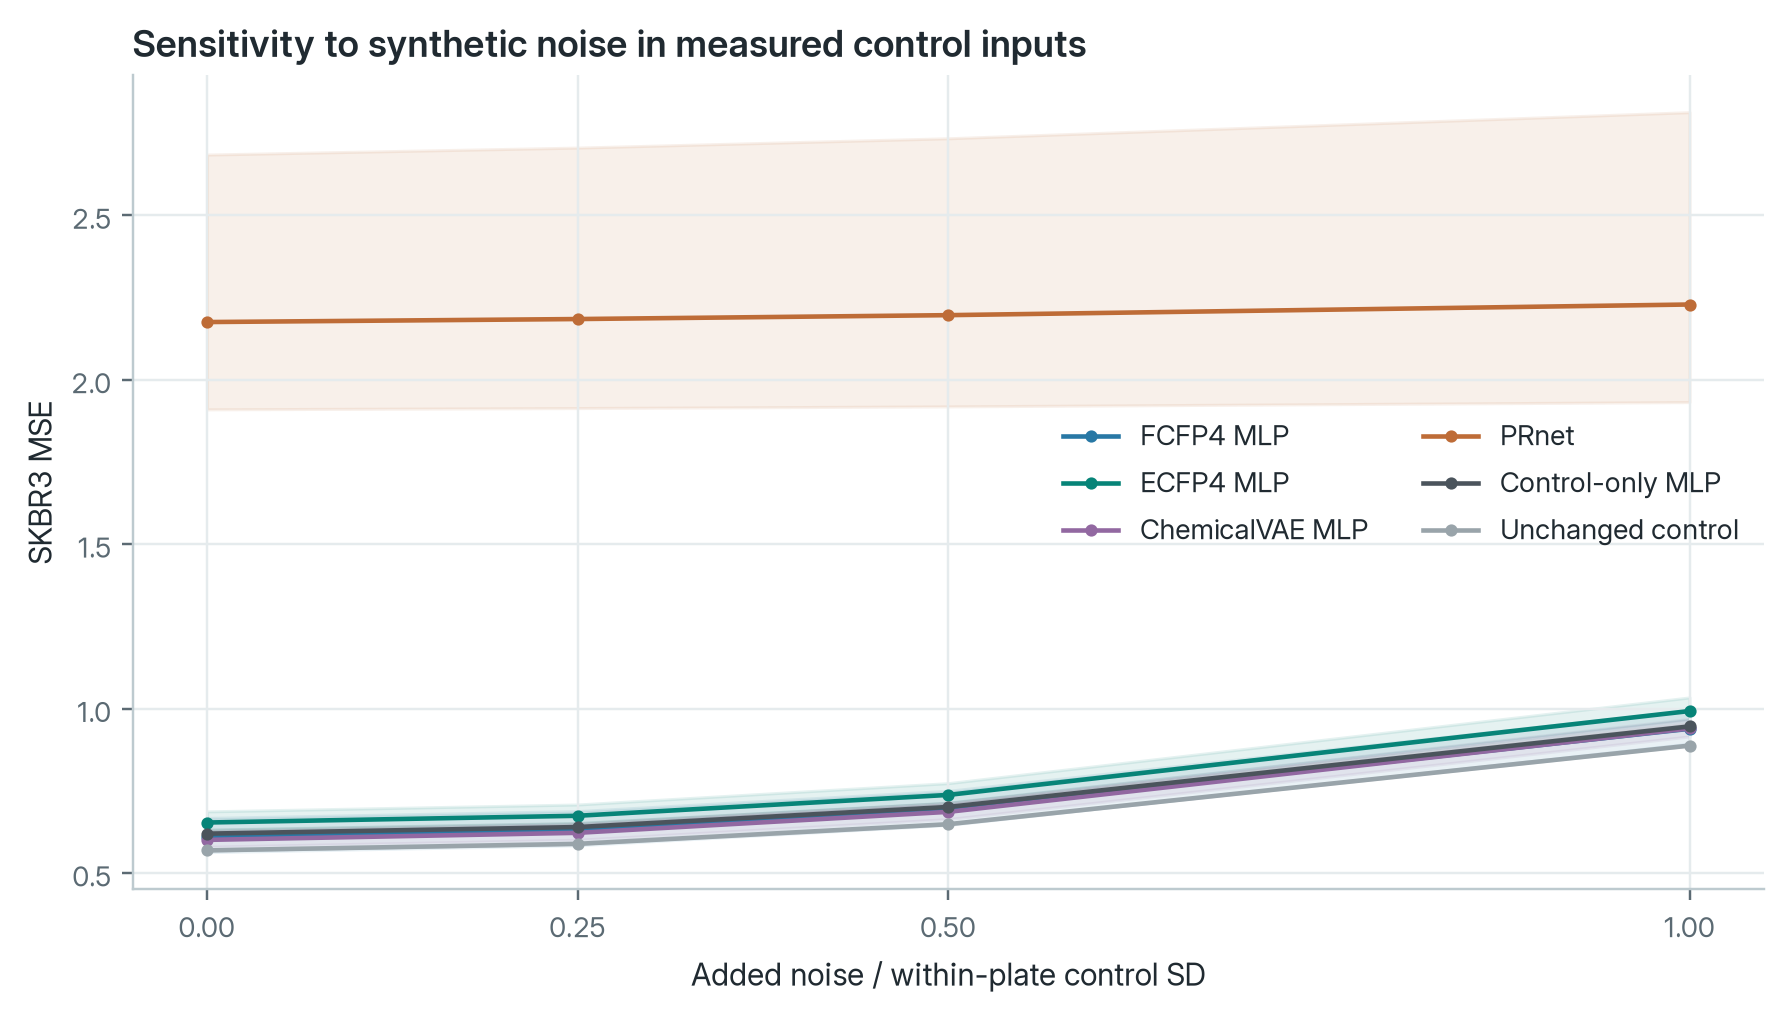

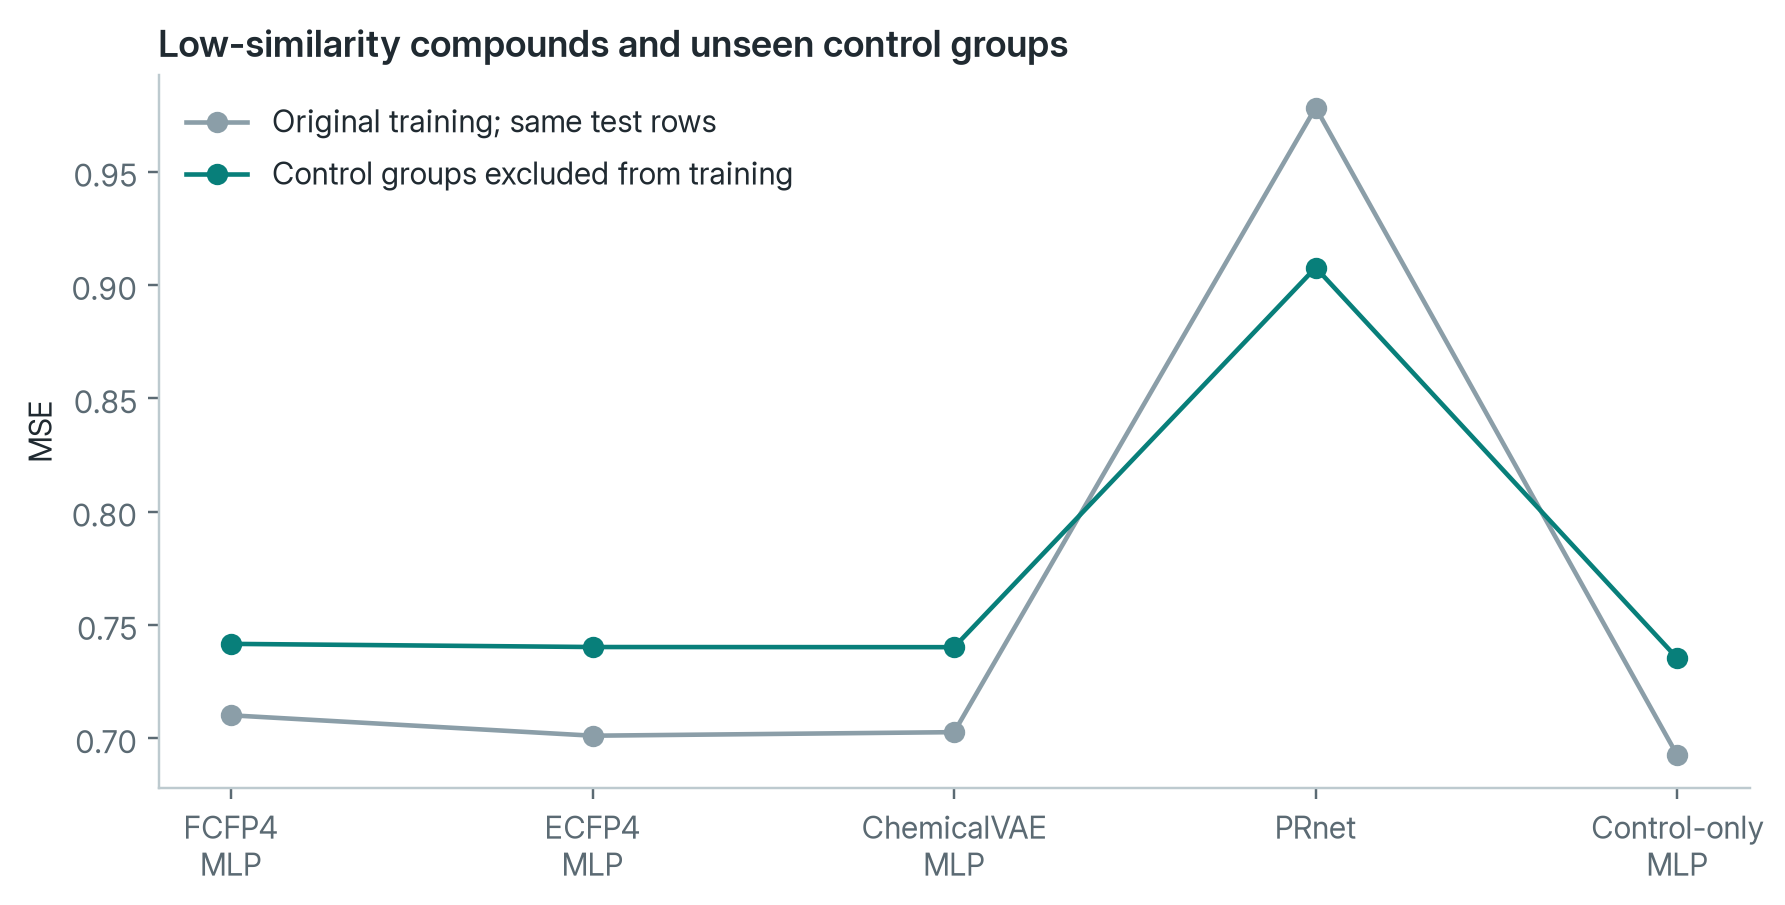

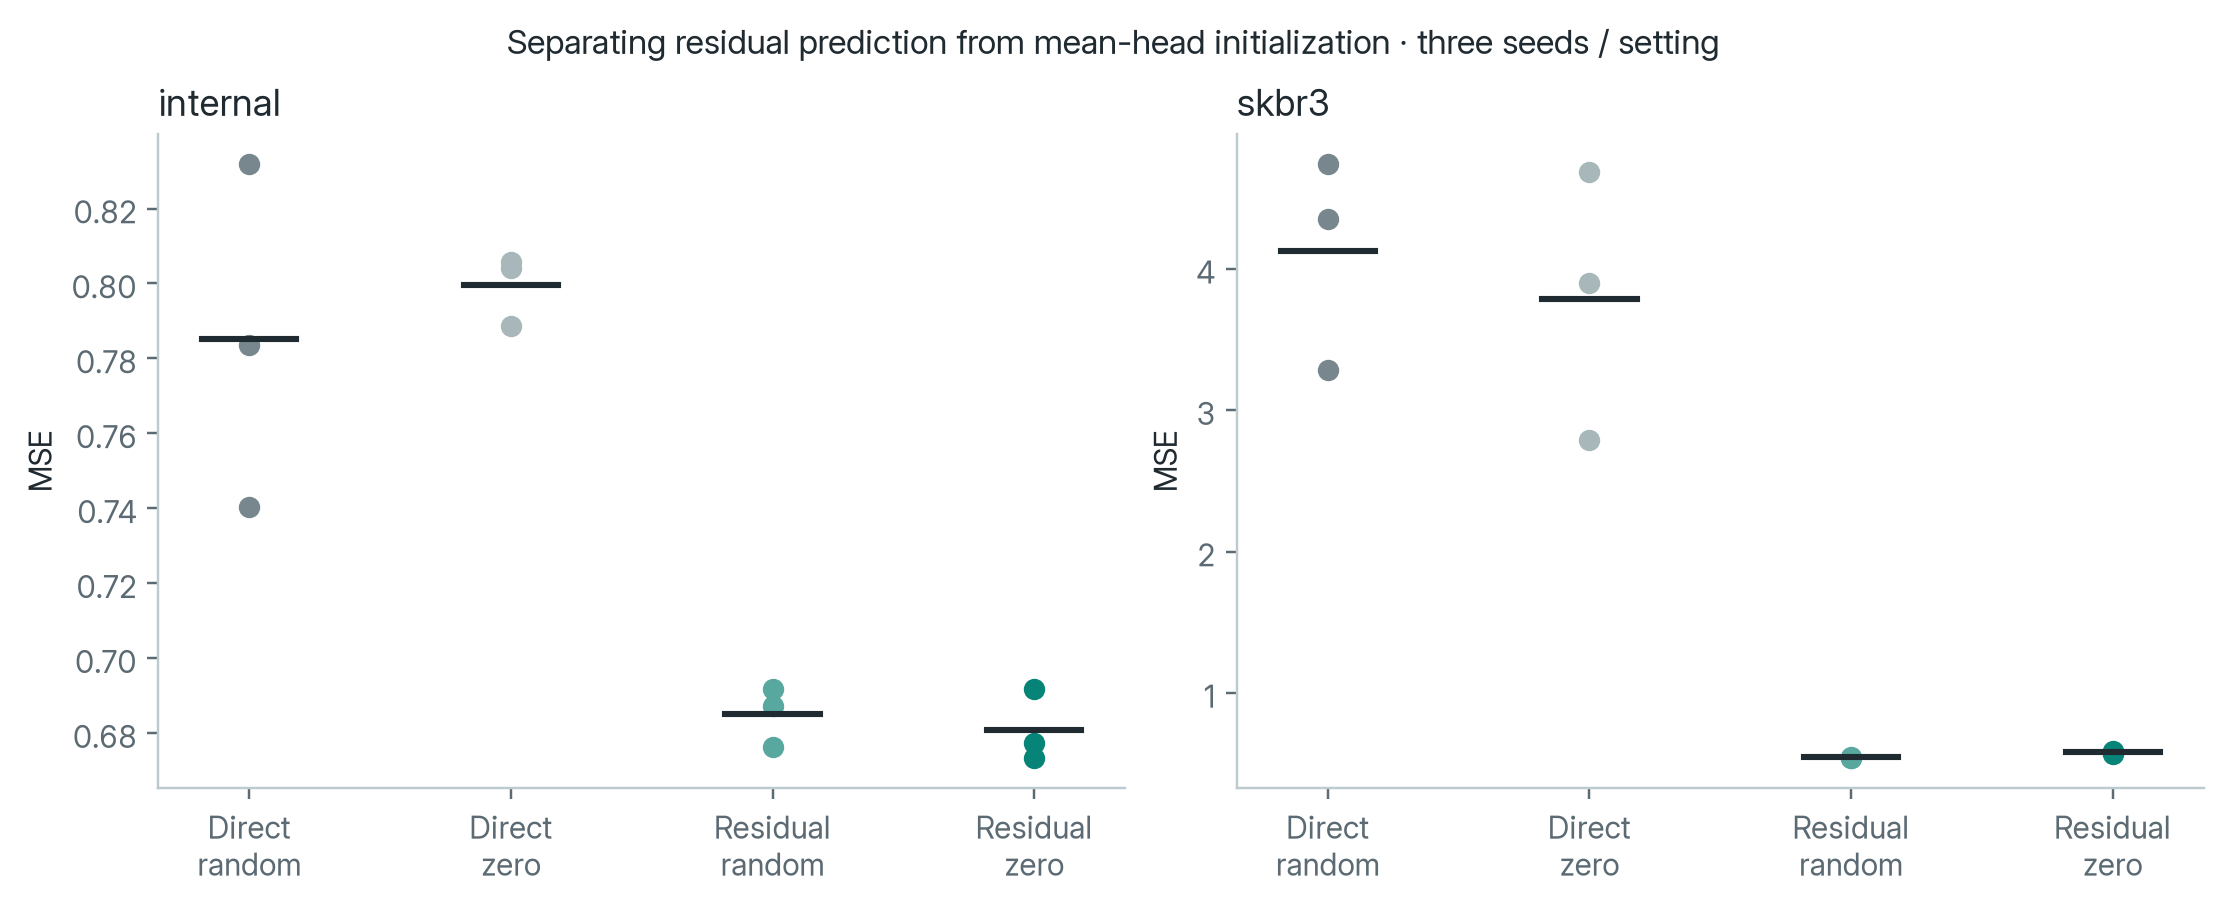

In [9]:
display(pd.read_csv(BALANCED / 'results/calibration.csv').groupby(['dataset','model'])[['nll','covered95','width95']].mean())
empirical = pd.read_csv(BALANCED / 'diagnostics/empirical_control_resampling.csv')
display(empirical.groupby('model')[['clean_mse','half_control_mse','prediction_rms_change']].mean())
display(Image(filename=str(PROJECT / 'presentation/figures/control_noise.png'), width=850))
display(Image(filename=str(PROJECT / 'presentation/figures/control_group_holdout.png'), width=850))
display(Image(filename=str(PROJECT / 'presentation/figures/residual_ablation.png'), width=1000))

## 8. Recompute tables or retrain

Run these commands from the project directory. They are not started automatically by this notebook. Checking and evaluation require the data and checkpoints from the full submission archive; see `docs/DATA.md`.

```sh
python run.py check
python run.py evaluate
```

To fit all models again:

```sh
python run.py train --fresh
```

Retraining is substantially longer than reading saved results. Fixed-setting models, validation tuning and joint holdout are separate result phases.

## 9. What the project can and cannot conclude

The results address the brief through tests of unseen compounds, SKBR3, the six external genes, model components and control noise. They can support a qualified conclusion about chemical input dependence and transfer in this cohort. They do not validate prospective drug-discovery utility, scaffold generalization, unseen doses or a broad range of new cell lines.

The next strongest experiment is a frozen independent external panel with matched dose/time and credible effect labels, followed by functional validation of compound rankings. Repeating training characterizes variability but does not provide independent experimental evidence.

See **Research_Report.pdf** for the full interpretation, code map and references. The motivating single-cell paper is literature context; the result figures here come from the project's bulk L1000 and GEO analyses.